# Phase 1 models - XGBoost against baselines

Project 19 (air quality forecasting via gradient boosting and LSTM models) - Team T024, Section A.

**Task.** Forecast hourly PM2.5 h hours ahead for h = 1, 6 and 24, with h = 6 as the headline. Direct strategy:
one model per horizon. Every input is known at the forecast origin t; only the label y(t+h) lies in the future.

**Rules.** Every choice (hyperparameters, target form, Ridge alpha, blend weights) is made on the validation folds
cv1 to cv3 (2011 to 2013) by pooled RMSE (`select` in the config). Both models train on squared error, which RMSE
measures, and on the same rows RMSE ranks models exactly as R2 does. MAE is reported next to it. The 2014 test year
is scored once, in step 11, behind `SCORE_TEST`.

**Order.** Run after `01_eda.ipynb` (why these features) and `02_data_preprocessing.ipynb` (the clean table read
here).

**Code.** The building blocks live in `src/aqf` and are unit tested (`tests/test_features.py`). This notebook
wires them together.

| File | What |
|---|---|
| `src/aqf/features.py` | `build` (features at t), `fold_xy` (train and eval sets per fold and horizon) |
| `src/aqf/models.py` | `baselines`, `fit_ridge`, `fit_xgb`, `anchor`, `sample_params`, `Forecaster` |
| `src/aqf/metrics.py` | `score`: MAE, RMSE, R2 and bias in µg/m³ |
| `configs/phase1.yaml` | horizons, feature settings, selection metric, search space, spike expert, seeds |

| Step | What | Why |
|---|---|---|
| 0 | setup | configs, cleaned frame, folds |
| 1 | features | lags, rolling, calendar, weather, derived, physics; all known at t |
| 2 | datasets | one train and eval set per fold and horizon, 24 h embargo |
| 3 | baselines | persistence and 24 h seasonal-naive, the bar to beat |
| 4 | Ridge | linear model on the same features |
| 5 | XGBoost search | random search over settings and target form (level or change), scored on cv1 to cv3 |
| 6 | XGBoost and ensembles | single model, seed ensemble, spike expert, blend |
| 7 | horizon sweep | skill vs persistence at 1, 3, 6, 12, 24 h |
| 8 | ablation | feature groups, target transform and form |
| 9 | importance | gain and permutation importance |
| 10 | error breakdown | seasons and episode hours |
| 11 | test 2014 | scored once with everything frozen |
| 12 | timings | how long each step took |

Runtime on an M3 Pro: about 6 minutes, mostly steps 5 and 8 (measured 2026-10-19). Step 12 shows the timings of
each run.

## 0. Setup

In [1]:
import hashlib
import json
import sys
import time
from contextlib import contextmanager
from functools import cache
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd

from aqf import viz
from aqf.config import load_config
from aqf.data.pipeline import run
from aqf.data.split import make_folds
from aqf.features import build, fold_xy
from aqf.metrics import score
from aqf.models import baselines, fit_ridge, fit_xgb, sample_params

%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 120)
pd.set_option("display.precision", 3)
viz.use_style()

dcfg = load_config("configs/data.yaml")
cfg = load_config("configs/phase1.yaml")
OUT = cfg["paths"]["out"]
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(dcfg["paths"]["interim"]) if dcfg["paths"]["interim"].exists() else run(dcfg)[0]
folds = make_folds(df.index, **dcfg["split"])
FOLD = {f["name"]: f for f in folds}
CVN = [f["name"] for f in folds if f["name"] != "test"]

H, HEAD = cfg["horizons"], cfg["headline"]
HS = sorted(set(H) | set(cfg["sweep"]))
assert max(HS) <= dcfg["split"]["gap_hours"], "the embargo must cover the longest horizon"
LOG, SMEAR, SEL, xc = cfg["log_target"], cfg["smear"], cfg["select"], cfg["xgb"]

TIMES = {}


@contextmanager
def timed(step):
    t0 = time.perf_counter()
    yield
    TIMES[step] = round(time.perf_counter() - t0, 1)
    print(f"{step}: {TIMES[step]} s")


df.shape, CVN, H, HEAD, SEL

((43824, 17), ['cv1', 'cv2', 'cv3'], [1, 6, 24], 6, 'rmse')

## 1. Features

`build` computes every feature at origin t from rows up to t only. Two more columns are added per fold and
horizon in step 2: `pm_anom` (PM2.5 minus the hour-of-day mean of that fold's training years) and the calendar
of the target hour t + h, which is known in advance.

| Group | Columns |
|---|---|
| lags | PM2.5 now and 1, 2, 3, 6, 12, 24, 48 h ago; missing flag now; missing hours in the last 24 h |
| rolling | mean, std, max over 3, 6, 12, 24 h; change over 1 and 3 h; `pm_anom` |
| calendar | hour and month as sin / cos, day of week, weekend, Lunar New Year eve and day |
| weather | dew point, temperature, pressure, wind speed, cumulative wind, rain, snow, wind direction, all from hour t - 1 |
| derived | relative humidity, pressure change over 3 and 24 h, hours since the wind changed direction, NW wind run over 24 h, from hour t - 1 |
| physics | stagnant hours in the last 24 h and the current stagnant run, SE wind run over 24 h, humid hours (RH above 80%) in the last 24 h, from hour t - 1 |

Weather is taken one hour before the origin (`weather_lag: 1`). The PM2.5 and weather clocks in the source data may be
offset by one hour (wiki open question Q15); the lag guarantees no weather input shares an hour with the target.

The physics group follows studies of Beijing winter episodes: pollution first arrives on southerly winds, then
builds up under weak winds, a shallow boundary layer and relative humidity above 80% (Zhong et al. 2018, ACP 18,
247-258). An hour counts as stagnant when the wind is below 3.2 m/s and no rain falls, the surface conditions of
the air stagnation index (Huang et al. 2018, ACP 18, 7573-7593), applied per hour here instead of per day. Trees
cannot build counts or run lengths from single-hour values, so these columns add memory the weather group lacks.
Boundary-layer height and spatial gradients are not in this dataset, so ventilation and advection terms are not
possible.

In [2]:
with timed("features"):
    F, groups = build(df, cfg["features"])
print(F.shape)
pd.DataFrame({"columns": {g: len(c) for g, c in groups.items()},
              "examples": {g: ", ".join(c[:4]) for g, c in groups.items()}})

features: 0.0 s
(43824, 44)


,columns,examples
lags,10,"pm_0, miss_0, miss_24, pm_lag1"
rolling,15,"pm_mean3, pm_std3, pm_max3, pm_mean6"
calendar,7,"hour_sin, hour_cos, month_sin, month_cos"
weather,11,"dewp, temp, pres, ws"
derived,5,"rh, dir_hours, nw_ws24, pres_diff3"
physics,4,"stag24, stag_run, se_ws24, humid24"


Causality check: deleting everything after an origin t must not change any feature row up to t.

In [3]:
t = pd.Timestamp("2012-07-19 13:00")
part, _ = build(df.loc[:t], cfg["features"])
pd.testing.assert_frame_equal(part, F.loc[:t])
"rows up to t are identical"

'rows up to t are identical'

## 2. Datasets

`fold_xy(F, df, fold, h)` returns `X_tr, y_tr, X_ev, y_ev`. Train origins stop 24 h before the eval year, so no
training label falls inside it. Eval rows need both the origin and the target inside the eval year, so no label
from a later year (in particular 2014) is ever scored during model selection. Eval rows also need an observed
label and both baselines, so all models are scored on exactly the same hours. Results are cached per (fold,
horizon). The test fold is not built until step 11.

In [4]:
@cache
def xy(name, h):
    return fold_xy(F, df, FOLD[name], h)


P = {}


def put(model, name, h, pred):
    P[(model, name, h)] = pd.Series(np.asarray(pred), index=xy(name, h)[3].index)


def pooled_y(h, names=CVN):
    return pd.concat([xy(n, h)[3] for n in names])


def pooled(model, h, names=CVN):
    return pd.concat([P[(model, n, h)] for n in names])


def pooled_score(h, preds):
    return score(pooled_y(h), np.concatenate([preds[n] for n in CVN]))


def table(models, hs, names=CVN):
    """Scores pooled over the given folds, with skill against persistence."""
    rows = []
    for h in hs:
        y = pooled_y(h, names)
        ref = score(y, pooled("persistence", h, names))
        for m in models:
            s = score(y, pooled(m, h, names))
            rows.append({"h": h, "model": m, **s,
                         "skill_mae": 1 - s["mae"] / ref["mae"], "skill_rmse": 1 - s["rmse"] / ref["rmse"]})
    return pd.DataFrame(rows).set_index(["h", "model"])


with timed("datasets"):
    sizes = pd.DataFrame([{"fold": n, "h": h, "train rows": len(xy(n, h)[1]), "eval rows": len(xy(n, h)[3]),
                           "features": xy(n, h)[0].shape[1]} for n in CVN for h in H])
sizes

datasets: 0.1 s


,fold,h,train rows,eval rows,features
0,cv1,1,8068,7720,52
1,cv1,6,8073,7688,52
2,cv1,24,8091,7742,52
3,cv2,1,16100,8124,52
4,cv2,6,16105,8106,52
5,cv2,24,16123,8105,52
6,cv3,1,24395,8640,52
7,cv3,6,24400,8623,52
8,cv3,24,24418,8622,52


## 3. Baselines

Persistence predicts y(t+h) = y(t). Seasonal-naive predicts y(t+h) = y(t+h-24), the same hour one day earlier.
At h = 24 the two are identical. Both use the causal input copy `pm25_in`.

In [5]:
with timed("baselines"):
    for h in HS:
        B = baselines(df, h)
        for n in CVN:
            for m in ["persistence", "seasonal"]:
                put(m, n, h, B.loc[xy(n, h)[3].index, m])
table(["persistence", "seasonal"], H)

baselines: 0.1 s


mae     rmse     r2   bias  skill_mae  skill_rmse
h  model                                                            
1  persistence  12.821   24.019  0.931  0.008      0.000       0.000
   seasonal     69.405  101.359 -0.229  0.098     -4.414      -3.220
6  persistence  40.231   65.772  0.483  0.057      0.000       0.000
   seasonal     69.424  101.417 -0.230  0.147     -0.726      -0.542
24 persistence  69.342  101.326 -0.229 -0.073      0.000       0.000
   seasonal     69.342  101.326 -0.229 -0.073      0.000       0.000

## 4. Ridge

A linear model on the same features: PM level columns are log1p-transformed, missing values are filled with
training medians, then standardised. Alpha and the target (log1p or raw) are chosen together by pooled RMSE on
cv1 to cv3.

In [6]:
with timed("ridge"):
    rows = []
    for h in H:
        for log in (True, False):
            for a in cfg["ridge_alphas"]:
                preds = {n: fit_ridge(xy(n, h)[0], xy(n, h)[1], a, log).predict(xy(n, h)[2]) for n in CVN}
                rows.append({"h": h, "log1p": log, "alpha": a, "preds": preds, **pooled_score(h, preds)})
    ridge = pd.DataFrame(rows)
    best = ridge.loc[ridge.groupby("h")[SEL].idxmin()]
    RIDGE = {int(r.h): (float(r.alpha), bool(r.log1p)) for r in best.itertuples()}
    for r in best.itertuples():
        for n in CVN:
            put("ridge", n, int(r.h), r.preds[n])
print("chosen (alpha, log1p target) per horizon:", RIDGE)
ridge.pivot_table(index=["log1p", "alpha"], columns="h", values=SEL)

ridge: 3.7 s
chosen (alpha, log1p target) per horizon: {1: (10.0, False), 6: (10.0, False), 24: (1000.0, False)}


h                  1       6       24
log1p alpha                          
False 0.1      23.078  57.670  82.439
      1.0      23.076  57.667  82.435
      10.0     23.072  57.665  82.404
      100.0    23.154  57.679  82.311
      1000.0   25.130  57.978  82.214
True  0.1      32.770  59.633  88.188
      1.0      32.965  59.636  88.188
      10.0     34.461  59.659  88.196
      100.0    46.308  59.799  88.258
      1000.0  114.814  60.567  88.414

## 5. XGBoost random search

`fit_xgb` early-stops on the last 90 days of the training span (with an h-hour gap before them), then refits on
the whole span with the chosen number of trees.

The same candidates are tried with two target forms:

- level: the model predicts y(t+h);
- change: the model predicts y(t+h) - y(t), and the forecast is PM2.5 now plus that change. This is the
  persistence-residual output of the AISEHack AFNO v4 model.

Trees predict averages of training targets, so a level model pulls peaks toward typical values and cannot go far
beyond the largest values it has seen. A change model starts from the current value and only learns how much it
moves. Each (form, candidate) pair is scored by pooled RMSE on cv1 to cv3, separately for every horizon. Search
space and number of candidates: `configs/phase1.yaml`.

In [7]:
cands = sample_params(xc["space"], xc["n_iter"], xc["search_seed"])


def xgb_cv(h, params, seed=0, cols=None, log=LOG, smear=SMEAR, delta=False, names=CVN):
    """Fit on each fold's training span and predict its eval year."""
    preds, trees = {}, []
    for n in names:
        X_tr, y_tr, X_ev, _ = xy(n, h)
        if cols is not None:
            keep = [c for c in X_tr.columns if c in cols]
            X_tr, X_ev = X_tr[keep], X_ev[keep]
        m, k = fit_xgb(X_tr, y_tr, {**xc["base"], **params}, xc["tail_hours"], h, log, smear, seed, delta)
        preds[n] = m.predict(X_ev)
        trees.append(k)
    return preds, trees


def seeds_cv(h, params, **kw):
    """Mean forecast over the ensemble seeds, the same averaging as `xgb_seeds`."""
    runs = [xgb_cv(h, params, seed=s, **kw)[0] for s in cfg["ensemble_seeds"]]
    return {n: np.mean([r[n] for r in runs], axis=0) for n in CVN}


with timed("xgb search"):
    rows = []
    for h in H:
        for d in (False, True):
            for i, p in enumerate(cands):
                preds, trees = xgb_cv(h, p, delta=d)
                rows.append({"h": h, "target": "change" if d else "level", "cand": i, **p,
                             **pooled_score(h, preds), "trees": int(np.mean(trees))})
        top = min((r for r in rows if r["h"] == h), key=lambda r: r[SEL])
        print(f"h={h}: best pooled {SEL} {top[SEL]:.2f} (candidate {top['cand']}, {top['target']} target)")
search = pd.DataFrame(rows)
best = search.loc[search.groupby("h")[SEL].idxmin()]
BEST = {int(r.h): cands[int(r.cand)] for r in best.itertuples()}
DELTA = {int(r.h): r.target == "change" for r in best.itertuples()}
search.to_csv(OUT / "cv_search.csv", index=False)
display(search.groupby(["h", "target"])[SEL].min().unstack())
search.sort_values(["h", SEL]).groupby("h").head(3)

h=1: best pooled rmse 22.54 (candidate 19, change target)


h=6: best pooled rmse 56.84 (candidate 4, level target)


h=24: best pooled rmse 83.30 (candidate 18, change target)
xgb search: 236.4 s


target,change,level
h,,
1,22.536,23.809
6,57.181,56.842
24,83.300,83.480


,h,target,cand,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,mae,rmse,r2,bias,trees
39,1,change,19,6,1,0.6,0.7,10.0,12.247,22.536,0.939,0.364,121
21,1,change,1,3,1,0.6,0.5,10.0,12.304,22.598,0.939,0.269,228
34,1,change,14,4,5,0.8,0.7,10.0,12.306,22.633,0.939,0.284,188
44,6,level,4,4,20,1.0,0.5,1.0,36.562,56.842,0.614,1.969,127
41,6,level,1,3,1,0.6,0.5,10.0,36.548,56.891,0.613,1.954,184
54,6,level,14,4,5,0.8,0.7,10.0,36.768,56.987,0.612,1.745,82
118,24,change,18,4,20,0.6,0.5,10.0,60.401,83.300,0.169,1.787,72
114,24,change,14,4,5,0.8,0.7,10.0,60.429,83.316,0.169,1.901,96
108,24,change,8,5,1,0.6,0.5,0.1,60.463,83.337,0.169,1.807,62


## 6. XGBoost and ensembles

- `xgb`: the best (form, candidate) with seed 0.
- `xgb_seeds`: the mean of the same model trained with 5 seeds. Row and column subsampling make the seeds differ,
  so averaging reduces variance.
- `spike`: the same settings trained with quantile loss at q = 0.9, so it aims high on purpose. This is the spike
  expert of the AISEHack model-1 and model-2 master blend, which mixed a stable model with a high-quantile one.
- `blend`: a * xgb_seeds + b * spike + c * ridge with a + b + c = 1 on a 0.1 grid, chosen by pooled RMSE on cv1 to
  cv3. b = 0 is the plain XGBoost + Ridge blend, so the spike expert only gets weight if it lowers RMSE.

The curvature correction of the AISEHack blend is not used: it was tuned to the competition score and has no
physical basis.

All cv numbers in this notebook are **selection scores**: settings, target form, Ridge alpha and blend weights are
chosen on the same folds they are scored on, so they are slightly optimistic. The honest number is the 2014 test.

In [8]:
MODELS = ["persistence", "seasonal", "ridge", "xgb", "xgb_seeds", "spike", "blend"]
STEP = np.round(np.linspace(0, 1, 11), 1)
GRID = [(float(a), float(b), float(abs(round(1 - a - b, 1)))) for a in STEP for b in STEP if a + b <= 1 + 1e-9]
SPIKE = xc["spike"]


def mix(h, w, names=CVN):
    """Blend of xgb_seeds, spike and ridge with weights w = (a, b, c)."""
    return {n: w[0] * P[("xgb_seeds", n, h)] + w[1] * P[("spike", n, h)] + w[2] * P[("ridge", n, h)]
            for n in names}


with timed("xgb seeds and spike"):
    for h in H:
        runs = [xgb_cv(h, BEST[h], seed=s, delta=DELTA[h])[0] for s in cfg["ensemble_seeds"]]
        spike = xgb_cv(h, {**BEST[h], **SPIKE}, delta=DELTA[h])[0]
        for n in CVN:
            put("xgb", n, h, runs[0][n])
            put("xgb_seeds", n, h, np.mean([r[n] for r in runs], axis=0))
            put("spike", n, h, spike[n])

BLEND = {}
for h in H:
    errs = [score(pooled_y(h), pd.concat(mix(h, w).values()))[SEL] for w in GRID]
    BLEND[h] = GRID[int(np.argmin(errs))]
    for n, p in mix(h, BLEND[h]).items():
        put("blend", n, h, p)

choices = {"select": SEL, "xgb": {str(h): BEST[h] for h in H},
           "xgb_target": {str(h): "change" if DELTA[h] else "level" for h in H}, "xgb_log_target": LOG,
           "ridge": {str(h): {"alpha": RIDGE[h][0], "log_target": RIDGE[h][1]} for h in H},
           "blend": {str(h): dict(zip(["xgb_seeds", "spike", "ridge"], BLEND[h])) for h in H}}
(OUT / "cv_choices.json").write_text(json.dumps(choices, indent=2))
print("blend weights (xgb_seeds, spike, ridge):", BLEND)
cv_scores = table(MODELS, H)
cv_scores.to_csv(OUT / "cv_scores.csv")
cv_scores

xgb seeds and spike: 31.7 s
blend weights (xgb_seeds, spike, ridge): {1: (0.7, 0.0, 0.3), 6: (0.6, 0.0, 0.4), 24: (0.3, 0.0, 0.7)}


mae     rmse     r2    bias  skill_mae  skill_rmse
h  model                                                              
1  persistence   12.821   24.019  0.931   0.008      0.000       0.000
   seasonal      69.405  101.359 -0.229   0.098     -4.414      -3.220
   ridge         13.151   23.072  0.936   0.393     -0.026       0.039
   xgb           12.247   22.536  0.939   0.364      0.045       0.062
   xgb_seeds     12.213   22.530  0.939   0.322      0.047       0.062
   spike         20.850   30.679  0.887  18.088     -0.626      -0.277
   blend         12.225   22.448  0.940   0.344      0.046       0.065
6  persistence   40.231   65.772  0.483   0.057      0.000       0.000
   seasonal      69.424  101.417 -0.230   0.147     -0.726      -0.542
   ridge         38.274   57.665  0.602   1.525      0.049       0.123
   xgb           36.562   56.842  0.614   1.969      0.091       0.136
   xgb_seeds     36.456   56.808  0.614   1.707      0.094       0.136
   spike         62.215   82.700  0.182  54.496     -0.546      -0.257
   blend         36.410   56.330  0.621   1.634      0.095       0.144
24 persistence   69.342  101.326 -0.229  -0.073      0.000       0.000
   seasonal      69.342  101.326 -0.229  -0.073      0.000       0.000
   ridge         60.300   82.214  0.191   1.642      0.130       0.189
   xgb           60.401   83.300  0.169   1.787      0.129       0.178
   xgb_seeds     60.557   83.631  0.163   1.941      0.127       0.175
   spike        109.234  136.538 -1.231  97.252     -0.575      -0.348
   blend         59.931   81.967  0.196   1.732      0.136       0.191

## 7. Horizon sweep

Skill = 1 - RMSE_model / RMSE_persistence on cv1 to cv3. h = 3 and h = 12 reuse the h = 6 settings and target
form, so they are slightly less tuned.

Skill alone does not pick a horizon: it keeps rising with h, because persistence gets worse faster than the
model. R2, the share of the variation a forecast explains, adds the other half of the argument:

- at 1 h persistence already explains most of the variation, so a model adds little;
- beyond 6 h even XGBoost explains less than half of it, so single forecasts are unreliable;
- 6 h is the longest horizon where XGBoost still explains more than half while clearly beating persistence.

The headline was fixed at 6 h from the EDA before any model was trained. This table supports that choice; it did
not make it.

horizon sweep: 2.8 s


rmse                  r2         skill_rmse       
model persistence     xgb persistence    xgb persistence    xgb
h                                                              
1          24.019  22.536       0.931  0.939         0.0  0.062
3          46.298  42.566       0.744  0.783         0.0  0.081
6          65.772  56.842       0.483  0.614         0.0  0.136
12         86.181  72.873       0.112  0.365         0.0  0.154
24        101.326  83.300      -0.229  0.169         0.0  0.178

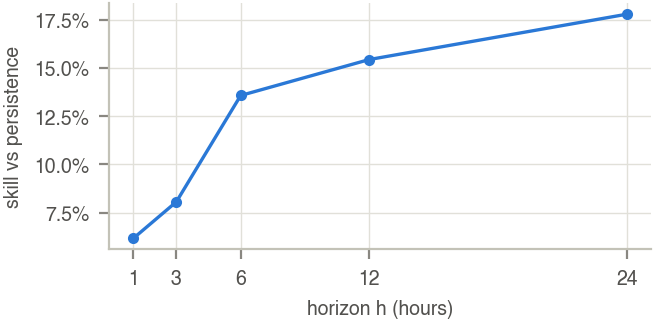

In [9]:
with timed("horizon sweep"):
    for h in HS:
        if ("xgb", CVN[0], h) not in P:
            preds, _ = xgb_cv(h, BEST[HEAD], delta=DELTA[HEAD])
            for n in CVN:
                put("xgb", n, h, preds[n])
sweep = table(["persistence", "xgb"], HS).reset_index()
sweep.to_csv(OUT / "cv_horizon_sweep.csv", index=False)
fig = viz.skill_by_horizon(sweep[sweep.model == "xgb"], f"skill_{SEL}")
sweep.pivot(index="h", columns="model", values=[SEL, "r2", f"skill_{SEL}"])

## 8. Ablation at the headline horizon

Feature groups are added one at a time in the order lags, rolling, calendar, weather, derived, physics; the last
row shows what the physics group adds on top of everything else. Then the target is compared with the chosen
settings: level on log1p, level on log1p with Duan's smearing correction, raw level and raw change. A negative
bias means the model predicts too low on average, which is the known catch of undoing log1p.

Every row is the mean forecast of the 5 ensemble seeds, with columns in their original order. With column
subsampling, a single fit moves when only the seed or the column order changes, by about as much as some feature
groups add, so single-seed rows are not comparable.

In [10]:
with timed("ablation"):
    rows, cols = [], []
    for g in groups:
        cols = cols + groups[g]
        preds = seeds_cv(HEAD, BEST[HEAD], cols=cols, delta=DELTA[HEAD])
        rows.append({"study": "features", "variant": f"+ {g}", "columns": len(cols), **pooled_score(HEAD, preds)})
    for name, log, smear, d in [("level, log1p", True, False, False), ("level, log1p + smearing", True, True, False),
                                ("level, raw", False, False, False), ("change, raw", False, False, True)]:
        preds = seeds_cv(HEAD, BEST[HEAD], log=log, smear=smear, delta=d)
        rows.append({"study": "target", "variant": name, "columns": len(cols), **pooled_score(HEAD, preds)})
ablation = pd.DataFrame(rows).set_index(["study", "variant"])
ablation.to_csv(OUT / "cv_ablation.csv")
ablation

ablation: 83.4 s


columns     mae    rmse     r2    bias
study    variant                                                        
features + lags                        10  39.874  62.051  0.540   0.119
         + rolling                     25  39.370  61.015  0.555   0.289
         + calendar                    32  38.802  60.157  0.567   0.224
         + weather                     43  36.832  58.021  0.597   1.140
         + derived                     48  36.523  57.170  0.609   1.268
         + physics                     52  36.456  56.808  0.614   1.707
target   level, log1p                  52  37.025  59.965  0.570 -12.628
         level, log1p + smearing       52  37.195  58.106  0.596   7.099
         level, raw                    52  36.456  56.808  0.614   1.707
         change, raw                   52  36.418  58.055  0.597   0.891

## 9. Feature importance at the headline horizon

Fitted on cv3 (training 2010 to 2012, the most data among the validation folds) and measured on 2013.

- Gain: how much each feature reduced the training loss inside the trees. Fast, but biased towards features with
  many split points.
- Permutation: how much the validation RMSE of the final forecast (µg/m³) worsens when one column is shuffled,
  averaged over 5 shuffles. Slower, but measured on unseen data. For a change model, shuffling `pm_0` also moves
  the value the change is added to, so its importance covers both roles.

In [11]:
def permutation(m, X, y, repeats=5, seed=0):
    """Mean increase of the selection metric when one column is shuffled."""
    rng = np.random.default_rng(seed)
    ref = score(y, m.predict(X))[SEL]
    out = {}
    for c in X.columns:
        errs = [score(y, m.predict(X.assign(**{c: rng.permutation(X[c].to_numpy())})))[SEL] - ref
                for _ in range(repeats)]
        out[c] = np.mean(errs)
    return pd.Series(out)


n = CVN[-1]
X_tr, y_tr, X_ev, y_ev = xy(n, HEAD)
with timed("importance"):
    m, _ = fit_xgb(X_tr, y_tr, {**xc["base"], **BEST[HEAD]}, xc["tail_hours"], HEAD, LOG, SMEAR, 0, DELTA[HEAD])
    gain = pd.Series(m.model.get_booster().get_score(importance_type="gain"))
    perm = permutation(m, X_ev, y_ev)
importance = pd.DataFrame({"gain": gain / gain.sum(), "permutation": perm})
importance = importance.fillna(0).sort_values("permutation", ascending=False)
importance.to_csv(OUT / "cv_importance.csv")
importance.head(15)

importance: 1.7 s


,gain,permutation
pm_anom,0.284,19.323
pm_0,0.092,2.354
stag_run,0.015,1.949
hour_cos,0.020,1.652
pm_mean24,0.029,1.492
stag24,0.024,1.394
pres_diff3,0.011,1.111
wd_se,0.015,1.044
month_cos,0.013,0.729
ws,0.011,0.727


## 10. Error breakdown at the headline horizon

Pooled over cv1 to cv3, split by season and by episode hours (observed PM2.5 above 150). Episodes are where the
large errors live, so this shows whether a model helps when it matters. The spike expert should help on episode
hours and cost elsewhere; the blend weights in step 6 decide how much of it to use.

In [12]:
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
y = pooled_y(HEAD)
season = y.index.month.map(SEASON).to_numpy()
subsets = [("all", np.ones(len(y), bool)), ("episode (y > 150)", (y > 150).to_numpy()),
           *[(s, season == s) for s in ["DJF", "MAM", "JJA", "SON"]]]
rows = []
for model in ["persistence", "ridge", "xgb_seeds", "spike", "blend"]:
    p = pooled(model, HEAD)
    for name, mask in subsets:
        s = score(y[mask], p[mask])
        rows.append({"subset": name, "model": model, "hours": int(mask.sum()),
                     "mae": s["mae"], "rmse": s["rmse"], "bias": s["bias"]})
bd = pd.DataFrame(rows)
bd.to_csv(OUT / "cv_breakdown.csv", index=False)
tab = bd.pivot(index="subset", columns="model", values=["rmse", "mae"])
tab[("hours", "")] = bd.groupby("subset")["hours"].first()
tab

rmse                                           mae                                        hours
model               blend persistence   ridge   spike xgb_seeds   blend persistence   ridge   spike xgb_seeds       
subset                                                                                                              
DJF                75.571      88.786  75.967  97.554    77.352  46.848      52.545  48.350  69.849    47.183   6064
JJA                45.683      51.569  47.455  74.369    45.474  32.124      34.240  33.815  60.247    32.085   6051
MAM                45.080      51.075  46.835  74.055    44.855  30.709      33.221  32.770  57.109    30.650   6000
SON                53.479      64.329  55.495  82.522    53.339  35.910      40.809  38.100  61.619    35.857   6302
all                56.330      65.772  57.665  82.700    56.808  36.410      40.231  38.274  62.215    36.456  24417
episode (y > 150)  87.084      89.213  86.755  75.968    89.391  64.572      65.041  64.877  56.181    65.621   5169

One episode in January 2013 (validation year of cv3), forecasts plotted at their target time.

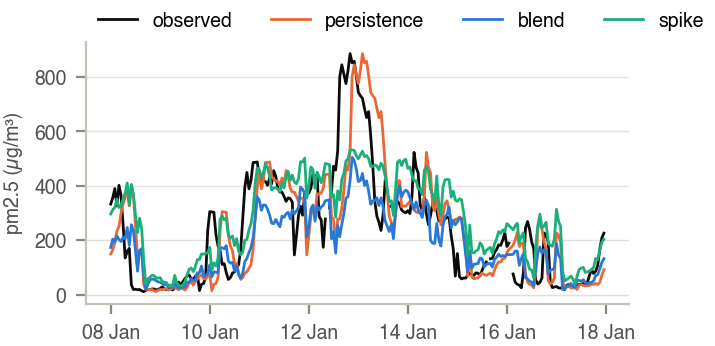

In [13]:
def at_target(model):
    s = P[(model, CVN[-1], HEAD)]
    return s.set_axis(s.index + pd.Timedelta(hours=HEAD))


fig = viz.forecast_window(df["pm25"], {m: at_target(m) for m in ["persistence", "blend", "spike"]},
                          "2013-01-08", "2013-01-17")

## 11. Test year 2014, scored once

Set `SCORE_TEST = True` only after every choice above is final (decision D16). Each model is retrained on 2010 to
2013 with the settings chosen on the validation folds and scored on 2014. Nothing in this step may feed back into
an earlier step. The cell refuses to run if 2014 was already scored, and it stores a fingerprint of the settings
used, so a second look at the test year cannot happen silently.

In [14]:
SCORE_TEST = True
DONE = OUT / "test_scores.csv"

if SCORE_TEST and DONE.exists():
    raise RuntimeError(f"2014 was already scored ({DONE}). Re-scoring turns the test year into a validation set.")
if SCORE_TEST:
    with timed("test 2014"):
        tn = "test"
        for h in H:
            X_tr, y_tr, X_ev, y_ev = xy(tn, h)
            B = baselines(df, h).loc[X_ev.index]
            put("persistence", tn, h, B["persistence"])
            put("seasonal", tn, h, B["seasonal"])
            put("ridge", tn, h, fit_ridge(X_tr, y_tr, *RIDGE[h]).predict(X_ev))
            runs = [xgb_cv(h, BEST[h], seed=s, delta=DELTA[h], names=[tn])[0][tn] for s in cfg["ensemble_seeds"]]
            put("xgb", tn, h, runs[0])
            put("xgb_seeds", tn, h, np.mean(runs, axis=0))
            put("spike", tn, h, xgb_cv(h, {**BEST[h], **SPIKE}, delta=DELTA[h], names=[tn])[0][tn])
            for n, p in mix(h, BLEND[h], [tn]).items():
                put("blend", n, h, p)
    test_scores = table(MODELS, H, ["test"])
    test_scores.to_csv(DONE)
    fingerprint = {"phase1.yaml": hashlib.sha256((ROOT / "configs/phase1.yaml").read_bytes()).hexdigest(),
                   "cv_choices.json": hashlib.sha256((OUT / "cv_choices.json").read_bytes()).hexdigest(),
                   "scored_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    (OUT / "test_fingerprint.json").write_text(json.dumps(fingerprint, indent=2))
    display(test_scores)
else:
    print("2014 not scored. Set SCORE_TEST = True once, after all choices are final.")

test 2014: 39.5 s


mae     rmse     r2    bias  skill_mae  skill_rmse
h  model                                                              
1  persistence   11.918   21.984  0.945  -0.020      0.000       0.000
   seasonal      67.356   98.869 -0.121   0.084     -4.652      -3.497
   ridge         12.005   21.409  0.947   0.578     -0.007       0.026
   xgb           11.279   20.744  0.951   0.320      0.054       0.056
   xgb_seeds     11.274   20.745  0.951   0.280      0.054       0.056
   spike         19.429   28.902  0.904  17.080     -0.630      -0.315
   blend         11.303   20.642  0.951   0.369      0.052       0.061
6  persistence   38.669   61.220  0.569  -0.144      0.000       0.000
   seasonal      67.298   98.740 -0.121   0.101     -0.740      -0.613
   ridge         36.106   54.198  0.662   2.427      0.066       0.115
   xgb           33.941   52.442  0.684   2.203      0.122       0.143
   xgb_seeds     33.789   52.211  0.687   2.284      0.126       0.147
   spike         56.278   76.092  0.334  49.741     -0.455      -0.243
   blend         33.930   51.963  0.690   2.341      0.123       0.151
24 persistence   67.487   99.020 -0.121   0.064      0.000       0.000
   seasonal      67.487   99.020 -0.121   0.064      0.000       0.000
   ridge         60.129   81.631  0.238   2.889      0.109       0.176
   xgb           60.237   83.227  0.208   2.170      0.107       0.159
   xgb_seeds     60.227   83.080  0.211   2.529      0.108       0.161
   spike        105.246  131.725 -0.984  95.116     -0.560      -0.330
   blend         59.783   81.493  0.241   2.781      0.114       0.177

## 12. Timings

In [15]:
(OUT / "timings.json").write_text(json.dumps(TIMES, indent=2))
pd.Series(TIMES, name="seconds").to_frame().assign(minutes=lambda d: (d.seconds / 60).round(1))

,seconds,minutes
features,0.0,0.0
datasets,0.1,0.0
baselines,0.1,0.0
ridge,3.7,0.1
xgb search,236.4,3.9
xgb seeds and spike,31.7,0.5
horizon sweep,2.8,0.0
ablation,83.4,1.4
importance,1.7,0.0
test 2014,39.5,0.7
